# Start Here: Math Notation Bridge (from high school to ML formulas)

> **Who is this for?** You remember some high-school math (fractions, powers, a graph of $y = 2x + 1$), you know a little Python, and the formulas in [`01_linear_algebra.ipynb`](01_linear_algebra.ipynb) to [`07_bayesian_ml.ipynb`](07_bayesian_ml.ipynb) look like a foreign language.
>
> **What you will learn**
> - How to *read* a formula out loud: variables, subscripts $x_i$, superscripts, hats $\hat{y}$, bars $\bar{x}$ and the Greek letters ML uses
> - Functions and their graphs: linear, quadratic, exponential, logarithm, the number $e$, the sigmoid
> - Summation $\Sigma$ and product $\Pi$ as `for` loops and as `np.sum` / `np.prod`; mean, variance, standard deviation
> - Vectors, matrices, the dot product, matrix-vector products, transpose and the shape rule
> - Derivatives as slope, the chain rule, partial derivatives, the gradient and **gradient descent**
> - Probability as frequency, conditional probability, Bayes' rule, the normal distribution, expectation
> - Translating four real ML formulas (MSE, linear model, softmax, cross-entropy) into NumPy, line by line
>
> **Prerequisites:** basic Python ([`../01_Python/01_basic.ipynb`](../01_Python/01_basic.ipynb)) and ideally a first look at NumPy ([`../02_Data_Analysis/02_numpy.ipynb`](../02_Data_Analysis/02_numpy.ipynb)). No university math needed.
>
> **Time needed:** about 2 to 3 hours (it is long: do one section per sitting if you like).
>
> **Runs on:** CPU, no API key, no internet. Libraries: `numpy`, `matplotlib`, `scikit-learn` (only to double-check two formulas).

### The one pattern used everywhere in this notebook

Every idea is shown four ways, in this order:

```
 plain English  -->  the math symbol  -->  the same thing in Python/NumPy  -->  a printed example or tiny plot
```

The point: a formula is just **a very short program written in an older language**. Once you can translate it into Python, you can test it, print it and plot it, and it stops being scary.

### Table of contents
1. Setup
2. How to read a formula (variables, subscripts, hats, bars, Greek letters)
3. Functions and their graphs (linear, quadratic, exponential, log, $e$, sigmoid)
4. Summation $\Sigma$ and product $\Pi$; mean, variance, standard deviation
5. Vectors and matrices (dot product, matrix-vector product, transpose, shape rule)
6. Derivatives, the chain rule, gradients and gradient descent
7. Probability basics (frequency, conditional probability, Bayes, normal distribution, expectation)
8. Formula to code: MSE, linear model, softmax, cross-entropy
9. Which math do I need for which part of the repo?
10. Recap, exercises, where to go next

---
## 1. Setup

We import the three tools we need:
- **NumPy** (`np`): fast arrays of numbers. Almost every formula in ML becomes one or two NumPy lines.
- **Matplotlib** (`plt`): drawing graphs.
- A fixed **random seed**: computers make "random" numbers from a starting value called a seed. Fixing it means you get the same "random" results as this notebook every time you run it.

In [1]:
import math                      # Python's built-in math functions (math.exp, math.log, ...)
import numpy as np               # numerical arrays
import matplotlib.pyplot as plt  # plotting

rng = np.random.default_rng(42)  # random number generator with a fixed seed -> repeatable results
np.set_printoptions(precision=4, suppress=True)  # print arrays with 4 decimals, no 1e-05 style

# a calm, consistent plot style (blue, orange, aqua for up to three lines)
plt.rcParams.update({
    "figure.figsize": (6, 3.6),             # default figure size in inches
    "axes.grid": True, "grid.alpha": 0.3,   # light background grid
    "axes.spines.top": False, "axes.spines.right": False,  # remove box top/right
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]),
    "lines.linewidth": 2,
})
print("NumPy version:", np.__version__)

NumPy version: 2.4.6


**What just happened?** We loaded the libraries and set up plotting defaults. Nothing mathematical yet; if you see a NumPy version printed, you are ready.

---
## 2. How to read a formula

### 2.1 Variables are just named boxes

**Plain English:** "The predicted price equals 300 dollars per square metre times the size, plus a base price of 20,000."

**Math:** $\hat{y} = w \, x + b$

**Read it out loud:** "y-hat equals w times x plus b."

| Symbol | Name | Meaning here |
|---|---|---|
| $x$ | a **variable** | the input (house size in square metres) |
| $w$ | a **weight** (also called a *parameter*) | how much each square metre adds (300) |
| $b$ | a **bias** (also called *intercept*) | the base price (20,000) |
| $\hat{y}$ | "y-hat" | the model's **prediction** (the hat means "estimated") |

In math, writing two letters next to each other ($w x$) means **multiply**. In Python you must write the `*`.

In [2]:
w = 300        # weight: dollars per square metre
b = 20_000     # bias: base price in dollars (underscores just make big numbers readable)
x = 85         # input: an 85 square-metre flat

y_hat = w * x + b   # math writes "w x"; Python needs the * sign
print("predicted price y_hat =", y_hat)

predicted price y_hat = 45500


**What just happened?** $\hat{y} = 300 \times 85 + 20000 = 45500$. A formula with letters is just a recipe; plug numbers in and you get a number out. Notice we named the Python variable `y_hat`: that is the usual way to type $\hat{y}$ in code.

### 2.2 Subscripts: $x_i$ means "item number $i$"

**Plain English:** "the 3rd value in the list."

**Math:** a small letter or number written low, $x_3$ or in general $x_i$ ("x sub i"), picks one item from a list $x_1, x_2, \dots, x_n$. Here $n$ is the number of items.

**Python:** `x[i]`. But watch out: math usually counts from **1**, Python always counts from **0**. So $x_1$ is `x[0]` and $x_n$ is `x[n-1]`.

Two subscripts, $X_{ij}$ ("X sub i j"), means "row $i$, column $j$" of a table, which in NumPy is `X[i, j]`.

In [3]:
x = np.array([4.0, 7.0, 1.0, 9.0])   # x_1, x_2, x_3, x_4 in math
n = len(x)                           # n = number of items
print("n =", n)
print("math x_1 -> Python x[0] =", x[0])
print("math x_3 -> Python x[2] =", x[2])

X = np.array([[1, 2, 3],             # a table with 2 rows and 3 columns
              [4, 5, 6]])
print("math X_23 (row 2, col 3) -> Python X[1, 2] =", X[1, 2])

try:
    print(x[n])                       # a beginner's translation of x_n ... off by one!
except IndexError as err:
    print("IndexError:", err)

n = 4
math x_1 -> Python x[0] = 4.0
math x_3 -> Python x[2] = 1.0
math X_23 (row 2, col 3) -> Python X[1, 2] = 6
IndexError: index 4 is out of bounds for axis 0 with size 4


**What just happened?** `x[0]` is the first item, which math calls $x_1$. The last line tried `x[4]` because $x_n = x_4$ in math, but Python has no position 4 in a list of 4 items (positions are 0, 1, 2, 3), so it raised an **IndexError**: *"index 4 is out of bounds for axis 0 with size 4"*. Read error messages like a sentence: it tells you which index (4) and what the size is (4).

> ⚠️ **Common mistake:** translating $x_n$ as `x[n]`. The last item is `x[n-1]`, or simply `x[-1]`.

### 2.3 Superscripts: a small raised symbol can mean three different things

| You see | Read as | Usually means | Python |
|---|---|---|---|
| $x^2$ | "x squared" | a power: $x \cdot x$ | `x**2` |
| $e^{x}$ | "e to the x" | the exponential function (Section 3) | `np.exp(x)` |
| $x^{(i)}$ (with brackets) | "x super i" | the $i$-th **example** in a dataset, *not* a power | `X[i]` (row $i$) |
| $A^T$ or $A^\top$ | "A transpose" | flip rows and columns (Section 5) | `A.T` |
| $A^{-1}$ | "A inverse" | the matrix that "undoes" $A$ | `np.linalg.inv(A)` |

Context tells you which meaning is intended: brackets around the superscript, as in $x^{(3)}$, almost always mean "example number 3".

> ⚠️ **Common mistake:** in Python `^` is **not** a power, it is a bitwise operation. `3 ^ 2` gives `1`, while `3 ** 2` gives `9`.

In [4]:
print("3 ** 2 =", 3 ** 2)   # power: what math means by 3^2
print("3 ^ 2  =", 3 ^ 2)    # bitwise XOR: NOT a power (a classic bug)

data = np.array([[1.70, 65],    # example 1: height (m), weight (kg)
                 [1.82, 80],    # example 2
                 [1.60, 52]])   # example 3
print("x^(2), the 2nd example (math counts from 1):", data[1])

3 ** 2 = 9
3 ^ 2  = 1
x^(2), the 2nd example (math counts from 1): [ 1.82 80.  ]


**What just happened?** `3 ** 2` is 9 (a power) but `3 ^ 2` is 1, a completely different operation. And $x^{(2)}$ in ML papers means "the whole second example", which is row `data[1]` in NumPy: `[1.82, 80.0]`.

### 2.4 Hats and bars

| You see | Read as | Meaning | Python name you will often see |
|---|---|---|---|
| $y$ | "y" | the **true** value (the label, the real answer) | `y`, `y_true` |
| $\hat{y}$ | "y-hat" | a **prediction** or **estimate** of $y$ | `y_hat`, `y_pred` |
| $\bar{x}$ | "x-bar" | the **mean** (average) of the $x$ values | `x_bar`, `x.mean()` |
| $\hat{\theta}$ | "theta-hat" | parameters **estimated** from data | `theta_hat` |

Rule of thumb: **hat = "our guess"**, **bar = "average"**.

In [5]:
y     = np.array([3.0, 5.0, 4.0])   # true exam scores
y_hat = np.array([2.5, 5.5, 4.0])   # a model's predicted scores
x_bar = y.mean()                    # y-bar would be the average true score

print("y     (truth)      :", y)
print("y_hat (prediction) :", y_hat)
print("errors y - y_hat   :", y - y_hat)
print("mean of y (y-bar)  :", x_bar)

y     (truth)      : [3. 5. 4.]
y_hat (prediction) : [2.5 5.5 4. ]
errors y - y_hat   : [ 0.5 -0.5  0. ]
mean of y (y-bar)  : 4.0


**What just happened?** The **error** of a prediction is $y - \hat{y}$: here $0.5$, $-0.5$ and $0$. Almost every "loss function" in ML (Section 8) is some way of turning these errors into a single number. The bar gave us the average, $4.0$.

### 2.5 The Greek letters you will meet in ML

Mathematicians ran out of Latin letters long ago, so ML borrows Greek ones. Each letter has a *usual* job. The job can change from paper to paper, so always check the text near the formula, but this table covers most cases in this repo.

| Letter | Pronounce | Usual meaning in ML | Where you will see it |
|---|---|---|---|
| $\alpha$ | "AL-fuh" | **learning rate** (step size); also a significance level in statistics (e.g. 0.05) | `06_optimization`, `04_statistics` |
| $\beta$ | "BAY-tuh" | regression **coefficients**; also momentum settings $\beta_1, \beta_2$ in the Adam optimizer | `01_linear_regression`, `06_optimization` |
| $\gamma$ | "GAM-uh" | **discount factor** in reinforcement learning; a kernel width in SVMs | `11_Reinforcement_Learning`, `05_svm` |
| $\delta$ | "DEL-tuh" | a **small change** or an error term | `02_calculus`, backpropagation |
| $\varepsilon$ (or $\epsilon$) | "EP-sih-lon" | a **tiny number** to avoid dividing by zero; random **noise**; exploration rate in RL | `06_optimization`, `08_industry_math_in_practice` |
| $\theta$ | "THAY-tuh" | **all the parameters** of a model bundled together | everywhere |
| $\lambda$ | "LAM-duh" | **regularization strength** (a penalty for big weights); also eigenvalues | `01_linear_algebra`, ridge/lasso |
| $\mu$ | "MYOO" | the **mean** (average) of a distribution | `03_probability`, `04_statistics` |
| $\sigma$ | "SIG-muh" | the **standard deviation** (spread); *also* the **sigmoid function** $\sigma(z)$ | `03_probability`, logistic regression |
| $\Sigma$ (capital sigma) | "capital SIG-muh" | "**add these up**" (summation); *also* a covariance matrix | Section 4 below |
| $\pi$ | "PIE" | the number 3.14159...; in RL a **policy** $\pi(a \mid s)$ | normal distribution, RL |
| $\nabla$ | "NAB-luh" or "del" | the **gradient**: the list of all slopes (Section 6) | `02_calculus`, `06_optimization` |
| $\partial$ | "partial" (or "del") | a **partial derivative**: slope in one direction only (Section 6) | `02_calculus` |

Two more you will meet: $\eta$ ("AY-tuh") is another common name for the learning rate, and $\Pi$ (capital pi) means "**multiply these together**" (Section 4).

In [6]:
# Greek letters are perfectly good Python variable names, but plain English names are clearer.
alpha = 0.1                 # learning rate (alpha)
lam = 0.01                  # regularization strength; NOT "lambda" (that word is reserved in Python)
mu, sigma = 170.0, 8.0      # mean and standard deviation of adult heights in cm (made-up numbers)
theta = np.array([0.5, -1.2, 3.0])  # all parameters of a model, bundled in one array

print(f"alpha={alpha}, lambda={lam}, mu={mu}, sigma={sigma}, theta={theta}")
print("pi =", np.pi)

try:
    exec("lambda = 0.01")   # try to use the reserved word as a variable name
except SyntaxError as err:
    print("SyntaxError:", err.msg)

alpha=0.1, lambda=0.01, mu=170.0, sigma=8.0, theta=[ 0.5 -1.2  3. ]
pi = 3.141592653589793
SyntaxError: invalid syntax


**What just happened?** Greek letters become ordinary variables. The one trap is $\lambda$: `lambda` is a reserved word in Python (it creates small anonymous functions), so assigning to it is a **SyntaxError**. People write `lam`, `lmbda` or `reg_strength` instead.

### 2.6 Other symbols you will see in notebooks 01 to 07

| Symbol | Read as | Meaning | Python |
|---|---|---|---|
| $x \in \mathbb{R}$ | "x is in the real numbers" | $x$ is an ordinary number (can have decimals) | a `float` |
| $\mathbf{v} \in \mathbb{R}^3$ | "v is in R three" | $\mathbf{v}$ is a list of 3 numbers (bold = vector) | `v.shape == (3,)` |
| $A \in \mathbb{R}^{m \times n}$ | "A is an m by n real matrix" | a table with $m$ rows and $n$ columns | `A.shape == (m, n)` |
| $\lVert \mathbf{v} \rVert$ | "the norm of v" | the length of a vector | `np.linalg.norm(v)` |
| $\approx$ | "approximately equal" | close, not exactly equal | `np.isclose(a, b)` |
| $\propto$ | "proportional to" | equal up to a constant factor | |
| $P(A \mid B)$ | "probability of A given B" | chance of $A$ when we know $B$ happened (Section 7) | |
| $X \sim \mathcal{N}(\mu, \sigma^2)$ | "X follows a normal distribution with mean mu, variance sigma squared" | how random values are spread (Section 7) | `rng.normal(mu, sigma)` |
| $\mathbb{E}[X]$ | "the expected value of X" | the long-run average (Section 7) | `samples.mean()` |
| $\mathcal{L}(\theta)$ | "the loss of theta" | how wrong the model with parameters $\theta$ is | a function returning one number |
| $\arg\min_\theta \mathcal{L}(\theta)$ | "arg-min over theta of L" | the $\theta$ that makes $\mathcal{L}$ smallest (not the smallest value itself) | `thetas[np.argmin(losses)]` |
| $f'(x)$ or $\frac{df}{dx}$ | "f prime of x", "d f d x" | the derivative (slope) of $f$ (Section 6) | |
| $A \odot B$ | "A Hadamard B" | multiply element by element | `A * B` |
| $AB$ | "A times B" | matrix multiplication (Section 5) | `A @ B` |

In [7]:
# arg min vs min: a tiny example
thetas = np.array([-2.0, -1.0, 0.0, 1.0, 2.0, 3.0])   # candidate parameter values
losses = (thetas - 1.0) ** 2                          # loss for each candidate
print("losses             :", losses)
print("min  (best loss)   :", losses.min())
print("argmin index       :", np.argmin(losses))
print("arg min theta      :", thetas[np.argmin(losses)])

losses             : [9. 4. 1. 0. 1. 4.]
min  (best loss)   : 0.0
argmin index       : 3
arg min theta      : 1.0


**What just happened?** $\min$ gives the **smallest loss** (0.0). $\arg\min$ gives **which input** produced it: $\theta = 1.0$. Training a model is exactly "find the $\arg\min$ of the loss", which is why you will see $\hat{\theta} = \arg\min_\theta \mathcal{L}(\theta)$ at the top of [`06_optimization.ipynb`](06_optimization.ipynb).

---
## 3. Functions and their graphs

**Plain English:** a **function** is a machine: a number goes in, a number comes out, and the same input always gives the same output.

**Math:** $f(x) = x^2 + 1$ ("f of x equals x squared plus one"). $f$ is the machine's name, $x$ is the input.

**Python:** a `def` with a `return`. NumPy functions also work on a whole array at once, which is how we get many points for a plot.

In [8]:
def f(x):
    return x**2 + 1          # f(x) = x^2 + 1

print("f(3) =", f(3))        # one input -> one output
xs = np.array([-2, -1, 0, 1, 2])
print("f(xs) =", f(xs))      # NumPy applies f to every element at once

f(3) = 10
f(xs) = [5 2 1 2 5]


**What just happened?** $f(3) = 3^2 + 1 = 10$. Passing a NumPy array gave five outputs in one call. That "apply to everything at once" trick is called **vectorization** and it is why NumPy code has so few loops.

### 3.1 The four shapes you meet most

| Name | Formula | Shape | Where in ML |
|---|---|---|---|
| **linear** | $f(x) = 2x + 1$ | a straight line | linear regression |
| **quadratic** | $f(x) = x^2$ | a U-shaped bowl | squared-error losses (they are bowls, which is why they are easy to minimize) |
| **exponential** | $f(x) = e^x$ | grows faster and faster, always positive | softmax, probabilities, growth |
| **logarithm** | $f(x) = \ln x$ | the "undo" of $e^x$; grows slower and slower; only for $x > 0$ | log-loss, log-likelihood |

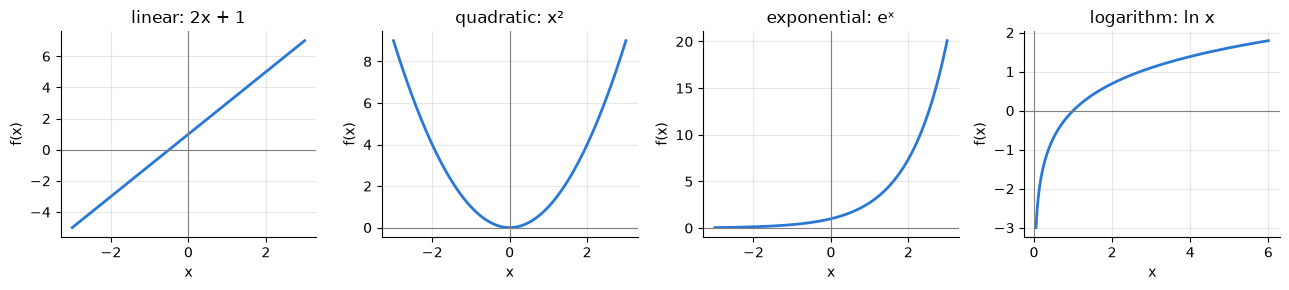

In [9]:
x = np.linspace(-3, 3, 200)            # 200 evenly spaced points from -3 to 3
x_pos = np.linspace(0.05, 6, 200)      # log only works for x > 0

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
axes[0].plot(x, 2 * x + 1);       axes[0].set_title("linear: 2x + 1")
axes[1].plot(x, x**2);            axes[1].set_title("quadratic: x²")
axes[2].plot(x, np.exp(x));       axes[2].set_title("exponential: eˣ")
axes[3].plot(x_pos, np.log(x_pos)); axes[3].set_title("logarithm: ln x")
for ax in axes:
    ax.set_xlabel("x"); ax.set_ylabel("f(x)")   # always label axes
    ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
plt.tight_layout(); plt.show()

**What just happened?** Four classic shapes. Note that $e^x$ is never negative and shoots up quickly, while $\ln x$ is only drawn for $x > 0$, crosses zero at $x = 1$ and dives towards $-\infty$ as $x$ approaches 0.

### 3.2 What is $e$, and what is $\ln$?

**$e \approx 2.71828$** is a number, like $\pi$. One way to meet it: put 1 dollar in a bank that pays 100% interest per year. If interest is added once a year you end with 2 dollars. Added twice a year (50% each time): $1.5^2 = 2.25$. Added $n$ times a year: $(1 + 1/n)^n$. As $n$ grows, this creeps up to $e$.

**$\ln x$** ("natural log of x", or "log x" in most ML papers) answers the question: *"$e$ to the power of what gives $x$?"*. So $\ln(e^3) = 3$. It undoes the exponential.

| Math | NumPy | Note |
|---|---|---|
| $e$ | `np.e` | |
| $e^x$, also written $\exp(x)$ | `np.exp(x)` | |
| $\ln x$, usually written just $\log x$ in ML | `np.log(x)` | `np.log` **is** the natural log |
| $\log_{10} x$ | `np.log10(x)` | |
| $\log_2 x$ | `np.log2(x)` | used for "bits" in information theory |

In [10]:
for n in [1, 2, 12, 365, 1_000_000]:
    print(f"interest added {n:>9} times a year -> (1 + 1/n)^n = {(1 + 1/n)**n:.6f}")
print("np.e                                          =", round(np.e, 6))

print("\nln(e^3) =", np.log(np.exp(3)))     # log undoes exp
print("ln(1)   =", np.log(1))               # e^0 = 1, so ln(1) = 0
print("log10(1000) =", np.log10(1000), "  log2(8) =", np.log2(8))

interest added         1 times a year -> (1 + 1/n)^n = 2.000000
interest added         2 times a year -> (1 + 1/n)^n = 2.250000
interest added        12 times a year -> (1 + 1/n)^n = 2.613035
interest added       365 times a year -> (1 + 1/n)^n = 2.714567
interest added   1000000 times a year -> (1 + 1/n)^n = 2.718280
np.e                                          = 2.718282

ln(e^3) = 3.0
ln(1)   = 0.0
log10(1000) = 3.0   log2(8) = 3.0


**What just happened?** As interest is added more often, the money approaches $e \approx 2.718282$. Then $\ln(e^3)$ gave back $3$, $\ln(1) = 0$ because $e^0 = 1$, $\log_{10}(1000) = 3$ and $\log_2(8) = 3$.

In [11]:
# What happens with log of 0 or a negative number?
try:
    math.log(0)                  # Python's math module refuses
except ValueError as err:
    print("math.log(0) -> ValueError:", err)

with np.errstate(divide="ignore", invalid="ignore"):   # silence NumPy's warnings for this demo
    print("np.log(0)  ->", np.log(0.0))    # NumPy returns minus infinity
    print("np.log(-1) ->", np.log(-1.0))   # NumPy returns nan = "not a number"

math.log(0) -> ValueError: math domain error
np.log(0)  -> -inf
np.log(-1) -> nan


**What just happened?** The log is only defined for positive numbers. Python's `math.log` raises a **ValueError** ("expected a positive input" or "math domain error", depending on your Python version), while NumPy quietly returns `-inf` or `nan` and (normally) prints a warning. This matters in ML: if a model predicts a probability of exactly 0 for the true class, the log-loss becomes infinite. Libraries avoid this by clipping probabilities to a tiny $\varepsilon$ such as $10^{-15}$.

### 3.3 Why logs turn products into sums

The key rule: $\log(a \times b) = \log a + \log b$.

**Why ML cares:** the probability of a whole dataset is often a **product** of many small probabilities (one per example). Multiplying 1,000 numbers like 0.01 gives a number so tiny the computer rounds it to 0 (**underflow**). Taking the log turns the product into a **sum** of manageable negative numbers. That is why you see "log-likelihood" everywhere in [`04_statistics.ipynb`](04_statistics.ipynb) and [`05_information_theory.ipynb`](05_information_theory.ipynb).

In [12]:
a, b = 8.0, 32.0
print("log(a*b)       =", np.log(a * b))
print("log(a) + log(b)=", np.log(a) + np.log(b))   # same number

probs = np.full(1000, 0.01)              # 1000 examples, each with probability 0.01
print("\nproduct of 1000 probabilities:", np.prod(probs))        # underflows to 0.0
print("sum of their logs            :", np.sum(np.log(probs)))   # perfectly fine

log(a*b)       = 5.545177444479562
log(a) + log(b)= 5.545177444479562

product of 1000 probabilities: 0.0
sum of their logs            : -4605.17018598809


**What just happened?** Both ways give $\log 256 \approx 5.5452$, confirming the rule. The true product $0.01^{1000} = 10^{-2000}$ is far smaller than the smallest number a 64-bit float can hold (about $10^{-308}$), so `np.prod` returned `0.0`. The sum of logs, about $-4605.17$, carries the same information without breaking.

### 3.4 The sigmoid: squashing any number into a probability

**Plain English:** take any number (from $-\infty$ to $+\infty$) and squash it smoothly into the range 0 to 1, so it can be read as a probability.

**Math:** $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ ("sigma of z"). Yes, this $\sigma$ is the *function*, not the standard deviation; context tells you.

**Where:** logistic regression ([`../03_Machine_Learning/01_supervised/02_logistic_regression.ipynb`](../03_Machine_Learning/01_supervised/02_logistic_regression.ipynb)) and neural networks.

sigmoid(-5) = 0.0067
sigmoid(-1) = 0.2689
sigmoid( 0) = 0.5000
sigmoid( 1) = 0.7311
sigmoid( 5) = 0.9933


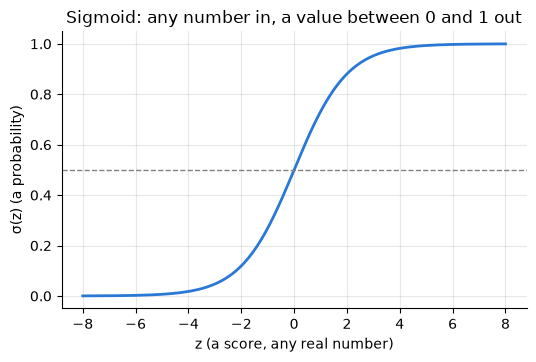

In [13]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))         # sigma(z) = 1 / (1 + e^(-z))

for z in [-5, -1, 0, 1, 5]:
    print(f"sigmoid({z:>2}) = {sigmoid(z):.4f}")

z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z))
plt.axhline(0.5, ls="--", color="gray", lw=1)   # the 50% line
plt.title("Sigmoid: any number in, a value between 0 and 1 out")
plt.xlabel("z (a score, any real number)"); plt.ylabel("σ(z) (a probability)")
plt.show()

**What just happened?** $\sigma(0) = 0.5$ exactly, big positive scores get close to 1 (e.g. $\sigma(5) \approx 0.9933$) and big negative scores get close to 0. A logistic regression model computes a score $z = w \cdot x + b$ and then reports $\sigma(z)$ as "the probability of class 1".

---
## 4. Summation $\Sigma$ and product $\Pi$

**Plain English:** "add up all the $x$ values."

**Math:**
$$\sum_{i=1}^{n} x_i = x_1 + x_2 + \dots + x_n$$
Read it as: "the sum, for $i$ from 1 to $n$, of x sub i". The bit under $\Sigma$ ($i=1$) is where the counter starts, the bit on top ($n$) is where it stops, and the bit on the right ($x_i$) is what you add each time.

**Python:** it is literally a `for` loop with a running total. NumPy does it in one call: `np.sum(x)`.

The product $\prod_{i=1}^{n} x_i = x_1 \times x_2 \times \dots \times x_n$ is the same idea with multiplication: `np.prod(x)`.

In [14]:
x = np.array([2.0, 4.0, 4.0, 5.0])

total = 0.0                     # the running total starts at 0 (nothing added yet)
for i in range(len(x)):         # i = 0, 1, 2, 3 in Python (math would say 1..4)
    total = total + x[i]        # add x_i
print("Sigma by loop   :", total)
print("Sigma by np.sum :", np.sum(x))

product = 1.0                   # a running product starts at 1, not 0!
for value in x:
    product = product * value
print("Pi by loop      :", product)
print("Pi by np.prod   :", np.prod(x))

print("Sum of squares, Sigma x_i^2:", np.sum(x**2))   # what is on the right gets computed first

Sigma by loop   : 15.0
Sigma by np.sum : 15.0
Pi by loop      : 160.0
Pi by np.prod   : 160.0
Sum of squares, Sigma x_i^2: 61.0


**What just happened?** The loop and `np.sum` agree: $2 + 4 + 4 + 5 = 15$. The product is $2 \times 4 \times 4 \times 5 = 160$. A running product starts at **1** (starting at 0 would make everything 0). The last line shows that $\sum_i x_i^2$ means "square each, then add": $4 + 16 + 16 + 25 = 61$.

### 4.1 Mean, variance and standard deviation: by hand, then NumPy

| Idea | Plain English | Formula |
|---|---|---|
| **mean** $\bar{x}$ (or $\mu$) | the balance point, the "typical" value | $\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$ |
| **variance** $\sigma^2$ | average **squared** distance from the mean | $\sigma^2 = \frac{1}{n}\sum_{i=1}^{n} (x_i - \bar{x})^2$ |
| **standard deviation** $\sigma$ | the typical distance from the mean, in the original units | $\sigma = \sqrt{\sigma^2}$ |

Why square the distances? Because distances above and below the mean would otherwise cancel out to exactly zero. The square root at the end brings the units back (from "dollars squared" to "dollars").

The **sample** variance, written $s^2$, divides by $n-1$ instead of $n$; it is the version used when your data is a sample from a bigger population ([`04_statistics.ipynb`](04_statistics.ipynb) explains why).

In [15]:
x = np.array([2.0, 4.0, 4.0, 4.0, 5.0, 5.0, 7.0, 9.0])   # 8 test scores
n = len(x)

x_bar = np.sum(x) / n                       # (1/n) * Sigma x_i
squared_dist = (x - x_bar) ** 2             # (x_i - x_bar)^2 for every i
var_pop = np.sum(squared_dist) / n          # divide by n   -> population variance
var_sample = np.sum(squared_dist) / (n - 1) # divide by n-1 -> sample variance
std_pop = np.sqrt(var_pop)                  # standard deviation

print("by hand : mean =", x_bar, " variance =", var_pop, " std =", std_pop)
print("NumPy   : mean =", x.mean(), " variance =", x.var(), " std =", x.std())
print("sample variance by hand =", round(var_sample, 4), "  NumPy x.var(ddof=1) =", round(x.var(ddof=1), 4))

by hand : mean = 5.0  variance = 4.0  std = 2.0
NumPy   : mean = 5.0  variance = 4.0  std = 2.0
sample variance by hand = 4.5714   NumPy x.var(ddof=1) = 4.5714


**What just happened?** Our hand-made formulas match NumPy exactly: mean 5.0, variance 4.0, standard deviation 2.0. The sample version (dividing by $n - 1 = 7$) is 4.5714. In NumPy the `ddof` argument ("delta degrees of freedom") picks the divisor: `ddof=0` divides by $n$, `ddof=1` divides by $n-1$.

> ⚠️ **Common mistake:** NumPy's `.std()` and `.var()` default to `ddof=0` (divide by $n$), while **pandas** `.std()` and `.var()` default to `ddof=1` (divide by $n-1$). Same data, slightly different numbers. Neither is a bug; just know which one you used.

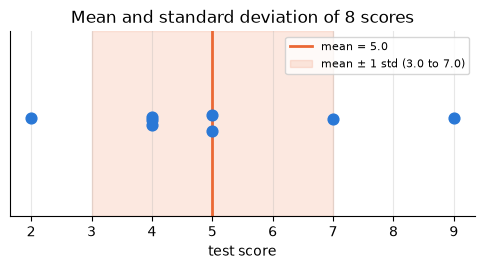

In [16]:
plt.figure(figsize=(6, 2.4))
plt.scatter(x, np.zeros_like(x) + rng.uniform(-0.05, 0.05, n), s=60, zorder=3)  # dots, tiny vertical jitter
plt.axvline(x_bar, color="#eb6834", label=f"mean = {x_bar}")                   # the mean
plt.axvspan(x_bar - std_pop, x_bar + std_pop, alpha=0.15, color="#eb6834",
            label=f"mean ± 1 std ({x_bar - std_pop} to {x_bar + std_pop})")    # one std each side
plt.yticks([]); plt.ylim(-0.5, 0.5)
plt.xlabel("test score"); plt.title("Mean and standard deviation of 8 scores")
plt.legend(loc="upper right", fontsize=8); plt.show()

**What just happened?** The orange line is the mean (5.0), and the shaded band covers one standard deviation on each side (3.0 to 7.0). Six of the eight scores fall inside the band (counting the 7 sitting on its edge); only 2 and 9 are outside. "Standard deviation" is simply the typical distance of a point from the mean.

---
## 5. Vectors and matrices

**Plain English:**
- A **vector** is an ordered list of numbers that describe one thing. A house might be `[size, bedrooms, age]`.
- A **matrix** is a table of numbers: in ML, usually **one row per example, one column per feature** (a **feature** is one measured property, like size).

**Math:** vectors are written in bold lowercase ($\mathbf{x}$), matrices in uppercase ($X$, $A$, $W$). The **shape** of a matrix is "rows $\times$ columns": $X \in \mathbb{R}^{3 \times 2}$ means 3 rows, 2 columns.

**Python:** `np.array`, and the `.shape` attribute tells you the shape. Checking `.shape` is the single most useful debugging habit in ML.

In [17]:
house = np.array([120.0, 3.0, 15.0])      # one house: size m², bedrooms, age in years
print("vector:", house, " shape:", house.shape)

X = np.array([[120.0, 3.0, 15.0],         # house 1
              [ 80.0, 2.0, 30.0],         # house 2
              [200.0, 5.0,  2.0],         # house 3
              [ 60.0, 1.0, 50.0]])        # house 4
print("matrix shape:", X.shape, "-> 4 rows (examples) x 3 columns (features)")
print("X[2]    (row 3, all features of house 3):", X[2])
print("X[:, 0] (column 1, the size of every house):", X[:, 0])

vector: [120.   3.  15.]  shape: (3,)
matrix shape: (4, 3) -> 4 rows (examples) x 3 columns (features)
X[2]    (row 3, all features of house 3): [200.   5.   2.]
X[:, 0] (column 1, the size of every house): [120.  80. 200.  60.]


**What just happened?** The vector has shape `(3,)`: 3 numbers. The matrix has shape `(4, 3)`: 4 houses, 3 features each. `X[2]` picked a whole row (one house) and `X[:, 0]` picked a whole column (one feature for all houses); the `:` means "everything along this axis".

### 5.1 The dot product is a weighted sum

**Plain English:** multiply matching items of two lists and add the results. If $\mathbf{w}$ holds "how much each feature is worth" and $\mathbf{x}$ holds one house's features, the dot product is the house's predicted price.

**Math:**
$$\mathbf{w} \cdot \mathbf{x} = \sum_{j=1}^{d} w_j x_j = w_1 x_1 + w_2 x_2 + \dots + w_d x_d$$
(also written $\mathbf{w}^T \mathbf{x}$). Here $d$ is the number of features.

**Python:** `np.dot(w, x)` or the matrix-multiply operator `w @ x`.

In [18]:
w = np.array([1500.0, 10000.0, -800.0])   # $ per m², $ per bedroom, $ per year of age (made up)
x = house                                  # [120, 3, 15]

by_loop = 0.0
for j in range(len(w)):
    by_loop += w[j] * x[j]                 # w_j * x_j, added up
print("loop      :", by_loop)
print("np.dot    :", np.dot(w, x))
print("w @ x     :", w @ x)
print("piece by piece:", w * x, "-> sum =", np.sum(w * x))

loop      : 198000.0
np.dot    : 198000.0
w @ x     : 198000.0
piece by piece: [180000.  30000. -12000.] -> sum = 198000.0


**What just happened?** All three give $1500 \cdot 120 + 10000 \cdot 3 - 800 \cdot 15 = 180000 + 30000 - 12000 = 198000$. The last line shows the two steps separately: `w * x` multiplies element by element, then `np.sum` adds. A dot product is a **weighted sum**: each feature contributes "value $\times$ importance". This is the core computation of linear regression, logistic regression and every neuron in a neural network.

### 5.2 A matrix-vector product is many dot products at once

**Plain English:** do the dot product above for every house (every row of $X$) in one go.

**Math:** $\hat{\mathbf{y}} = X\mathbf{w}$, where entry $i$ is $\hat{y}_i = \sum_j X_{ij} w_j$ (row $i$ of $X$ dotted with $\mathbf{w}$).

**Python:** `X @ w`.

In [19]:
prices_loop = np.array([np.dot(X[i], w) for i in range(X.shape[0])])  # one dot product per row
prices = X @ w                                                       # all rows at once
print("row by row:", prices_loop)
print("X @ w     :", prices)
print("shapes: X", X.shape, "@ w", w.shape, "->", prices.shape)

row by row: [198000. 116000. 348400.  60000.]
X @ w     : [198000. 116000. 348400.  60000.]
shapes: X (4, 3) @ w (3,) -> (4,)


**What just happened?** `X @ w` returned four predicted prices, one per house, identical to the loop. Shapes: $(4, 3)$ times $(3,)$ gives $(4,)$. When you read $X\mathbf{w}$ in a paper, picture "every row dotted with $\mathbf{w}$".

### 5.3 Transpose: flip rows and columns

**Math:** $X^T$ ("X transpose"). Row $i$ of $X$ becomes column $i$ of $X^T$, so a $(4 \times 3)$ matrix becomes $(3 \times 4)$.

**Python:** `X.T`

In [20]:
A = np.array([[1, 2, 3],
              [4, 5, 6]])
print("A, shape", A.shape); print(A)
print("A.T, shape", A.T.shape); print(A.T)

A, shape (2, 3)
[[1 2 3]
 [4 5 6]]
A.T, shape (3, 2)
[[1 4]
 [2 5]
 [3 6]]


**What just happened?** The first row `[1, 2, 3]` became the first column. Transposes appear constantly to make shapes line up, e.g. $X^T X$ in the linear regression formula in [`01_linear_algebra.ipynb`](01_linear_algebra.ipynb).

### 5.4 The shape rule for matrix multiplication

To multiply $A$ (shape $m \times n$) by $B$ (shape $n \times p$), **the inside numbers must match**, and the result has the **outside numbers**:

```
   A        @     B        =     C
 (m x n)       (n x p)        (m x p)
      \_______/
     must be equal
```

Each entry $C_{ik}$ is row $i$ of $A$ dotted with column $k$ of $B$, which is why the row length of $A$ ($n$) must equal the column length of $B$ ($n$).

In [21]:
A = np.ones((4, 3))          # 4 x 3
B = np.ones((3, 2))          # 3 x 2
print("(4x3) @ (3x2) ->", (A @ B).shape)    # inside 3 = 3, result is 4 x 2

C = np.ones((4, 2))          # 4 x 2
try:
    A @ C                    # (4x3) @ (4x2): inside numbers 3 and 4 do not match
except ValueError as err:
    print("ValueError:", err)

print("fix with a transpose: (4x3).T @ (4x2) = (3x4) @ (4x2) ->", (A.T @ C).shape)

(4x3) @ (3x2) -> (4, 2)
ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 4 is different from 3)
fix with a transpose: (4x3).T @ (4x2) = (3x4) @ (4x2) -> (3, 2)


**What just happened?** $(4 \times 3) @ (3 \times 2)$ worked and gave $(4 \times 2)$. Then $(4 \times 3) @ (4 \times 2)$ failed with a **ValueError**. The message says something like *"matmul: Input operand 1 has a mismatch in its core dimension 0 ... (size 4 is different from 3)"*: NumPy is telling you the inside numbers (3 and 4) differ. Transposing $A$ fixed it. When a shape error appears, write the shapes side by side like the diagram above; the fix is usually a transpose or a reshape.

> 💡 **Tip:** `*` and `@` are different. `A * B` multiplies element by element (shapes must match or "broadcast"), `A @ B` is matrix multiplication (inside numbers must match). In math, $A \odot B$ is `A * B` and $AB$ is `A @ B`.

---
## 6. Derivatives, the chain rule, gradients and gradient descent

### 6.1 A derivative is a slope

**Plain English:** "if I nudge the input a tiny bit, how much does the output change, per unit of nudge?" It is the steepness of the graph at one point. Positive slope: going uphill to the right. Negative: downhill. Zero: flat (the bottom of a bowl, for example).

**Math:**
$$f'(x) = \frac{df}{dx} \approx \frac{f(x + h) - f(x)}{h} \quad \text{for a very small } h$$
("f prime of x", "d f by d x"). The exact derivative is what this ratio approaches as $h$ shrinks to 0. For $f(x) = x^2$ the rule from school is $f'(x) = 2x$.

**Python:** just compute the ratio with a small `h`. This is called a **numerical derivative**.

In [22]:
def f(x):
    return x**2                          # f(x) = x^2

def numerical_derivative(func, x, h=1e-5):
    return (func(x + h) - func(x)) / h   # rise over run for a tiny step h

for x0 in [-2.0, 0.0, 1.0, 3.0]:
    print(f"x = {x0:>4}:  numerical slope = {numerical_derivative(f, x0):.5f}   exact 2x = {2*x0}")

x = -2.0:  numerical slope = -3.99999   exact 2x = -4.0
x =  0.0:  numerical slope = 0.00001   exact 2x = 0.0
x =  1.0:  numerical slope = 2.00001   exact 2x = 2.0
x =  3.0:  numerical slope = 6.00001   exact 2x = 6.0


**What just happened?** The tiny-step ratio matches the school rule $2x$ to about 4 decimal places (the leftover difference, about $0.00001$, equals $h$ itself; a smaller $h$ shrinks it, until rounding errors take over, see [`08_industry_math_in_practice.ipynb`](08_industry_math_in_practice.ipynb)). At $x = 0$ the slope is 0: the bottom of the bowl.

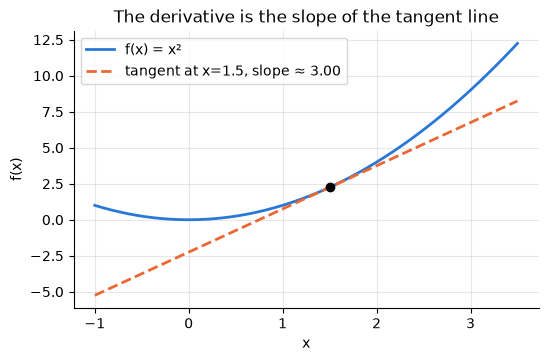

In [23]:
x0 = 1.5                                    # the point where we want the tangent line
slope = numerical_derivative(f, x0)         # about 3.0
xs = np.linspace(-1, 3.5, 200)
tangent = f(x0) + slope * (xs - x0)         # the straight line touching the curve at x0

plt.plot(xs, f(xs), label="f(x) = x²")
plt.plot(xs, tangent, "--", label=f"tangent at x={x0}, slope ≈ {slope:.2f}")
plt.scatter([x0], [f(x0)], color="black", zorder=3)
plt.title("The derivative is the slope of the tangent line")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.legend(); plt.show()

**What just happened?** The dashed **tangent line** just touches the curve at $x = 1.5$ and has slope $\approx 3.00$ (exactly $2 \times 1.5 = 3$). Zoom in far enough on any smooth curve and it looks like this straight line; the derivative is that line's slope.

### 6.2 The chain rule: slopes multiply through a chain

**Plain English:** if $y$ depends on $u$, and $u$ depends on $x$, then "how fast $y$ changes with $x$" = "how fast $y$ changes with $u$" **times** "how fast $u$ changes with $x$". Think of gears: if gear A turns gear B 3 times as fast, and B turns C 2 times as fast, then A turns C $3 \times 2 = 6$ times as fast.

**Math:** for $y = g(u)$ and $u = h(x)$,
$$\frac{dy}{dx} = \frac{dy}{du} \cdot \frac{du}{dx}$$

**Example:** $y = (3x + 1)^2$. Inner: $u = 3x + 1$ so $\frac{du}{dx} = 3$. Outer: $y = u^2$ so $\frac{dy}{du} = 2u$. Chain: $\frac{dy}{dx} = 2u \cdot 3 = 6(3x + 1)$.

**Why ML cares:** a neural network is a long chain of functions. **Backpropagation** (in [`02_calculus.ipynb`](02_calculus.ipynb)) is just the chain rule applied from the output back to every weight.

In [24]:
def y_of_x(x):
    return (3 * x + 1) ** 2               # the whole chain

x0 = 2.0
u = 3 * x0 + 1                            # inner value u = 7
dy_du = 2 * u                             # outer slope: derivative of u^2 is 2u = 14
du_dx = 3                                 # inner slope: derivative of 3x+1 is 3
print("chain rule  dy/du * du/dx =", dy_du, "*", du_dx, "=", dy_du * du_dx)
print("numerical derivative     =", round(numerical_derivative(y_of_x, x0), 3))

chain rule  dy/du * du/dx = 14.0 * 3 = 42.0
numerical derivative     = 42.0


**What just happened?** At $x = 2$: $u = 7$, the outer slope is $14$, the inner slope is $3$, so the chain rule says $42$. The numerical derivative agrees (about $42.000$). That is all backpropagation does, just with millions of links in the chain.

### 6.3 Partial derivatives and the gradient

**Plain English:** when a function has **several inputs**, ask "what is the slope if I nudge **only one** input and hold the others still?" That is a **partial derivative**. Collect the partial derivatives for every input into one vector and you have the **gradient**: an arrow that points in the direction of steepest **uphill**.

**Math:** for $f(x, y) = x^2 + 3y^2$,
$$\frac{\partial f}{\partial x} = 2x, \qquad \frac{\partial f}{\partial y} = 6y, \qquad \nabla f = \begin{bmatrix} 2x \\ 6y \end{bmatrix}$$
Read $\frac{\partial f}{\partial x}$ as "partial f, partial x" and $\nabla f$ as "grad f" or "del f". When taking $\frac{\partial f}{\partial x}$ we treat $y$ like a constant number, so the $3y^2$ part has slope 0 in the $x$ direction.

**Python:** nudge one input at a time.

In [25]:
def f2(p):                                 # p = [x, y], a point on the map
    x, y = p
    return x**2 + 3 * y**2

def numerical_gradient(func, p, h=1e-5):
    p = np.asarray(p, dtype=float)
    grad = np.zeros_like(p)
    for k in range(len(p)):                # one input at a time
        step = np.zeros_like(p); step[k] = h
        grad[k] = (func(p + step) - func(p)) / h   # nudge only input k
    return grad

point = np.array([1.0, 2.0])
print("numerical gradient at (1, 2):", numerical_gradient(f2, point))
print("formula [2x, 6y]            :", np.array([2 * point[0], 6 * point[1]]))

numerical gradient at (1, 2): [ 2. 12.]
formula [2x, 6y]            : [ 2. 12.]


**What just happened?** At the point $(1, 2)$ the gradient is about $[2, 12]$: the function climbs 2 units per step in $x$ and 12 per step in $y$. The surface is much steeper in the $y$ direction. In ML the "inputs" of the loss function are the model's **weights**, and the gradient tells us how each weight affects the error.

### 6.4 Gradient descent: walking downhill

**Plain English:** you are on a foggy hill and want the lowest point. You cannot see far, but you can feel the slope under your feet. So: feel the slope, take a small step **downhill**, repeat. That is **gradient descent**, the algorithm that trains almost every ML model.

**Math:** the update rule (from [`06_optimization.ipynb`](06_optimization.ipynb)):
$$\theta_{t+1} = \theta_t - \alpha \, \nabla \mathcal{L}(\theta_t)$$
"new parameters = old parameters minus learning-rate times gradient". The minus sign means "go *against* the uphill arrow", i.e. downhill. $\alpha$ (the **learning rate**) is the step size; the subscript $t$ counts steps.

**1-D example:** minimize $\mathcal{L}(w) = (w - 3)^2$, whose bottom is at $w = 3$. Its derivative is $2(w - 3)$.

In [26]:
def loss(w):
    return (w - 3) ** 2              # a bowl with its bottom at w = 3

def grad(w):
    return 2 * (w - 3)               # its slope

w = -4.0                             # a bad starting guess
alpha = 0.2                          # learning rate (step size)
path = [w]
for t in range(12):
    w = w - alpha * grad(w)          # theta_{t+1} = theta_t - alpha * gradient
    path.append(w)
    if t < 5 or t == 11:
        print(f"step {t+1:>2}: w = {w:8.4f}   loss = {loss(w):.6f}")

step  1: w =  -1.2000   loss = 17.640000
step  2: w =   0.4800   loss = 6.350400
step  3: w =   1.4880   loss = 2.286144
step  4: w =   2.0928   loss = 0.823012
step  5: w =   2.4557   loss = 0.296284
step 12: w =   2.9848   loss = 0.000232


**What just happened?** Starting from $w = -4$ (loss 49), each step moves $w$ closer to 3 and the loss shrinks: after one step $w = -1.2$, after 12 steps $w \approx 2.9848$ with a loss of about $0.0002$. Steps get smaller automatically because the slope gets flatter near the bottom.

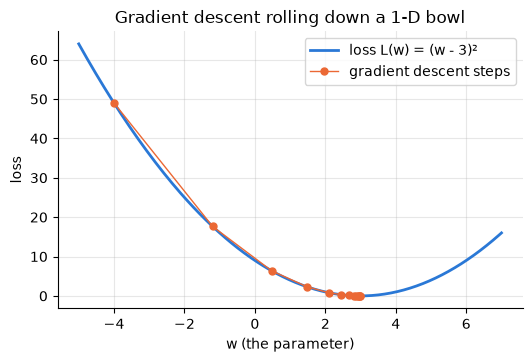

In [27]:
ws = np.linspace(-5, 7, 200)
plt.plot(ws, loss(ws), label="loss L(w) = (w - 3)²")
path = np.array(path)
plt.plot(path, loss(path), "o-", ms=5, lw=1, color="#eb6834", label="gradient descent steps")
plt.title("Gradient descent rolling down a 1-D bowl")
plt.xlabel("w (the parameter)"); plt.ylabel("loss"); plt.legend(); plt.show()

**What just happened?** The orange dots are the successive guesses: big jumps at first where the bowl is steep, tiny ones near the bottom at $w = 3$.

In [28]:
# What if the learning rate is too big?
for alpha_try in [0.05, 0.2, 0.9, 1.1]:
    w = -4.0
    for t in range(12):
        w = w - alpha_try * grad(w)
    print(f"alpha = {alpha_try:<4}: w after 12 steps = {w:12.4f}")

alpha = 0.05: w after 12 steps =       1.0230
alpha = 0.2 : w after 12 steps =       2.9848
alpha = 0.9 : w after 12 steps =       2.5190
alpha = 1.1 : w after 12 steps =     -59.4127


**What just happened?** With $\alpha = 0.05$ we are still crawling (about $1.02$, not yet at 3), $\alpha = 0.2$ gets close ($\approx 2.98$), $\alpha = 0.9$ zig-zags from one side of the bowl to the other and is only at about $2.52$ (it does converge, slowly), and $\alpha = 1.1$ **overshoots more each step and explodes** (about $-59.4$, moving further away every step). Choosing the learning rate is one of the first knobs you turn when training neural networks.

**2-D example:** minimize $\mathcal{L}(x, y) = (x - 1)^2 + 3(y + 2)^2$, whose lowest point is at $(1, -2)$. The gradient is $\nabla \mathcal{L} = [\,2(x-1),\; 6(y+2)\,]$. We draw the landscape as a **contour plot**: like a hiking map, each ring joins points of equal height.

In [29]:
def loss2(x, y):
    return (x - 1) ** 2 + 3 * (y + 2) ** 2      # bowl with bottom at (1, -2)

def grad2(p):
    x, y = p
    return np.array([2 * (x - 1), 6 * (y + 2)]) # [dL/dx, dL/dy]

p = np.array([-3.0, 2.0])                       # start far from the bottom
alpha = 0.1
path2 = [p.copy()]
for t in range(25):
    p = p - alpha * grad2(p)                    # same update rule, now with a vector
    path2.append(p.copy())
path2 = np.array(path2)
print("start:", path2[0], " after 25 steps:", path2[-1].round(4), " loss:", round(loss2(*path2[-1]), 6))

start: [-3.  2.]  after 25 steps: [ 0.9849 -2.    ]  loss: 0.000228


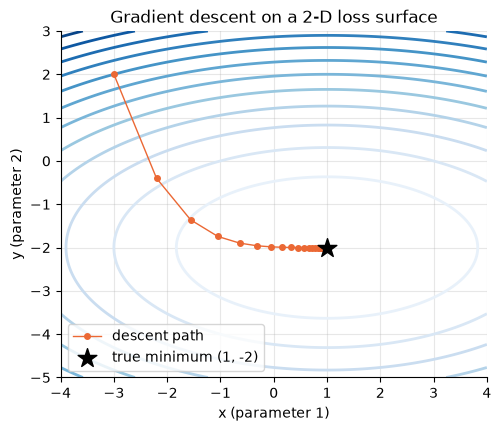

In [30]:
gx, gy = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-5, 3, 200))   # a grid of (x, y) points
plt.figure(figsize=(5.5, 4.5))
cs = plt.contour(gx, gy, loss2(gx, gy), levels=15, cmap="Blues")         # height rings
plt.plot(path2[:, 0], path2[:, 1], "o-", ms=4, lw=1, color="#eb6834", label="descent path")
plt.scatter([1], [-2], marker="*", s=200, color="black", zorder=3, label="true minimum (1, -2)")
plt.title("Gradient descent on a 2-D loss surface")
plt.xlabel("x (parameter 1)"); plt.ylabel("y (parameter 2)"); plt.legend(loc="lower left"); plt.show()

**What just happened?** After 25 steps from $(-3, 2)$ we reached about $(0.9849, -2.0)$, very close to the true minimum $(1, -2)$. The path first drops quickly in $y$ (the steep direction, slope 6 per unit) and then slides along the shallow $x$ direction. A real model does exactly this, just with thousands or billions of parameters instead of 2.

---
## 7. Probability basics

### 7.1 Probability as long-run frequency

**Plain English:** "the probability of heads is 0.5" means: flip the coin many, many times and about half the flips will be heads.

**Math:** $P(\text{heads}) = 0.5$ ("P of heads"). Probabilities are between 0 (never) and 1 (always), and the probabilities of all possible outcomes add up to 1.

**Python:** simulate it! `rng.integers` and `rng.random` make random numbers.

after     10 flips: fraction of heads = 0.6000
after    100 flips: fraction of heads = 0.5300
after   1000 flips: fraction of heads = 0.5110
after  10000 flips: fraction of heads = 0.4939


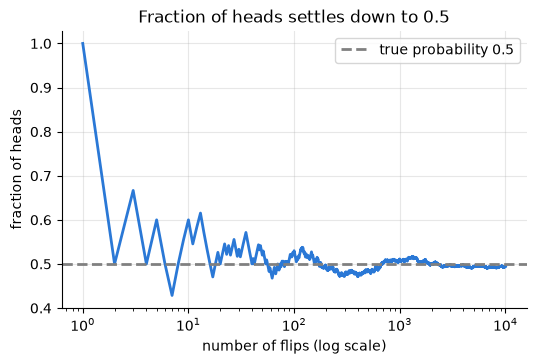

In [31]:
flips = rng.integers(0, 2, size=10_000)                 # 0 = tails, 1 = heads, 10,000 flips
running = np.cumsum(flips) / np.arange(1, len(flips) + 1)  # fraction of heads so far after each flip
for k in [10, 100, 1_000, 10_000]:
    print(f"after {k:>6} flips: fraction of heads = {running[k-1]:.4f}")

plt.plot(np.arange(1, len(flips) + 1), running)
plt.axhline(0.5, ls="--", color="gray", label="true probability 0.5")
plt.xscale("log")                                       # log scale shows early and late flips together
plt.title("Fraction of heads settles down to 0.5")
plt.xlabel("number of flips (log scale)"); plt.ylabel("fraction of heads"); plt.legend(); plt.show()

**What just happened?** With only 10 flips the fraction can be far from 0.5, but with 10,000 it is very close (you should see roughly 0.49 to 0.51). This settling down is the **law of large numbers** ([`03_probability.ipynb`](03_probability.ipynb), section 11).

In [32]:
rolls = rng.integers(1, 7, size=60_000)                  # 60,000 rolls of a fair six-sided die
faces, counts = np.unique(rolls, return_counts=True)     # how often did each face appear?
freq = counts / len(rolls)
for face, fr in zip(faces, freq):
    print(f"face {face}: frequency {fr:.4f}   (theory 1/6 = {1/6:.4f})")
print("P(roll is even) estimated:", round(np.mean(rolls % 2 == 0), 4), "(theory 0.5)")

face 1: frequency 0.1674   (theory 1/6 = 0.1667)
face 2: frequency 0.1664   (theory 1/6 = 0.1667)
face 3: frequency 0.1655   (theory 1/6 = 0.1667)
face 4: frequency 0.1668   (theory 1/6 = 0.1667)
face 5: frequency 0.1682   (theory 1/6 = 0.1667)
face 6: frequency 0.1658   (theory 1/6 = 0.1667)
P(roll is even) estimated: 0.499 (theory 0.5)


**What just happened?** Each face shows up close to $1/6 \approx 0.1667$ of the time. The last line estimates the probability of an **event** (a set of outcomes, here "even") as "the fraction of trials where it happened". `np.mean` of a True/False array gives exactly that fraction.

### 7.2 Conditional probability and Bayes' rule, by counting

**Conditional probability** $P(A \mid B)$, read "probability of A **given** B": among only the cases where $B$ happened, what fraction also had $A$?
$$P(A \mid B) = \frac{\text{number of cases with both } A \text{ and } B}{\text{number of cases with } B}$$

**A medical test** (made-up but realistic numbers):
- 1% of people have the disease (this is called the **prevalence** or **base rate**).
- If you have it, the test is positive 90% of the time (the **sensitivity**).
- If you do *not* have it, the test is still positive 9% of the time (the **false positive rate**).

**Question:** you test positive. What is the chance you actually have the disease, $P(\text{sick} \mid \text{positive})$? Most people guess "about 90%". Let us count with an imaginary town of 10,000 people.

In [33]:
town = 10_000
sick = town * 0.01                      # 1% have the disease -> 100 people
healthy = town - sick                   # 9,900 people

sick_and_pos = sick * 0.90              # 90% of the sick test positive  -> 90
healthy_and_pos = healthy * 0.09        # 9% of the healthy test positive -> 891
all_pos = sick_and_pos + healthy_and_pos

print(f"sick: {sick:.0f}, healthy: {healthy:.0f}")
print(f"positive tests: {sick_and_pos:.0f} sick + {healthy_and_pos:.0f} healthy = {all_pos:.0f}")
print(f"P(sick | positive) = {sick_and_pos:.0f} / {all_pos:.0f} = {sick_and_pos / all_pos:.4f}")

sick: 100, healthy: 9900
positive tests: 90 sick + 891 healthy = 981
P(sick | positive) = 90 / 981 = 0.0917


**What just happened?** Of the 981 people who test positive, only 90 are actually sick, so $P(\text{sick} \mid \text{positive}) = 90 / 981 \approx 0.0917$, about **9%**, not 90%! The disease is so rare that the 9% false positives among the 9,900 healthy people (891 people) swamp the 90 true positives. This "base-rate" effect matters for every classifier you build on rare events (fraud, disease, defects).

**Bayes' rule** is the same counting, written as a formula:
$$P(\text{sick} \mid +) = \frac{P(+ \mid \text{sick}) \; P(\text{sick})}{P(+)}, \qquad P(+) = P(+ \mid \text{sick})P(\text{sick}) + P(+ \mid \text{healthy})P(\text{healthy})$$

| Piece | Name | Value |
|---|---|---|
| $P(\text{sick})$ | **prior**: belief before the test | 0.01 |
| $P(+ \mid \text{sick})$ | **likelihood**: how well the evidence fits | 0.90 |
| $P(+)$ | **evidence**: overall chance of a positive | computed below |
| $P(\text{sick} \mid +)$ | **posterior**: belief after the test | ? |

These four words are exactly the ones used at the top of [`07_bayesian_ml.ipynb`](07_bayesian_ml.ipynb).

In [34]:
p_sick = 0.01                   # prior
p_pos_given_sick = 0.90         # sensitivity (likelihood)
p_pos_given_healthy = 0.09      # false positive rate

p_pos = p_pos_given_sick * p_sick + p_pos_given_healthy * (1 - p_sick)   # evidence
posterior = p_pos_given_sick * p_sick / p_pos                            # Bayes' rule
print(f"P(+) = {p_pos:.4f}   P(sick | +) by Bayes = {posterior:.4f}")

# and a third way: simulate 1,000,000 random people
people = 1_000_000
is_sick = rng.random(people) < p_sick                                    # True for about 1%
test_pos = np.where(is_sick, rng.random(people) < p_pos_given_sick,      # sick: positive 90% of the time
                             rng.random(people) < p_pos_given_healthy)   # healthy: positive 9% of the time
print(f"simulated P(sick | +) = {is_sick[test_pos].mean():.4f}")

P(+) = 0.0981   P(sick | +) by Bayes = 0.0917
simulated P(sick | +) = 0.0913


**What just happened?** The formula gives $P(+) = 0.0981$ and the posterior $0.0917$, exactly our count. The simulation of a million random people lands very close to it (you should see roughly 0.09). Three routes, one answer: **Bayes' rule is just organised counting.**

### 7.3 The normal distribution (the bell curve)

**Plain English:** many measurements (heights, measurement errors, test scores) cluster around an average, with values further away becoming rarer, symmetrically on both sides.

**Math:** $X \sim \mathcal{N}(\mu, \sigma^2)$ ("X is normally distributed with mean mu and variance sigma squared"). Its curve, the **probability density function**, is
$$p(x) = \frac{1}{\sigma\sqrt{2\pi}} \, e^{-\frac{(x - \mu)^2}{2\sigma^2}}$$
Don't panic: it is the shape $e^{-(\text{distance})^2}$, scaled so that the total area under the curve is 1. The height of the curve is not itself a probability; **areas** under it are.

**Python:** draw samples with `rng.normal(mu, sigma, size)`, and type the formula directly.

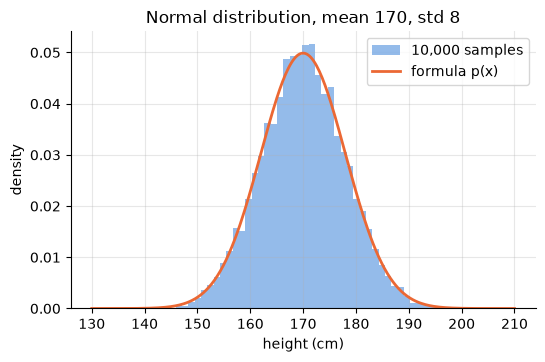

within 1 std of the mean: 0.684
within 2 std of the mean: 0.956
within 3 std of the mean: 0.998


In [35]:
mu, sigma = 170.0, 8.0                                     # heights in cm (made-up)
samples = rng.normal(mu, sigma, size=10_000)              # 10,000 random heights

def normal_pdf(x, mu, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-((x - mu) ** 2) / (2 * sigma**2))

xs = np.linspace(130, 210, 300)
plt.hist(samples, bins=50, density=True, alpha=0.5, label="10,000 samples")   # density=True: area 1
plt.plot(xs, normal_pdf(xs, mu, sigma), label="formula p(x)")
plt.title("Normal distribution, mean 170, std 8")
plt.xlabel("height (cm)"); plt.ylabel("density"); plt.legend(); plt.show()

for k in [1, 2, 3]:                                        # the 68-95-99.7 rule
    inside = np.mean(np.abs(samples - mu) < k * sigma)
    print(f"within {k} std of the mean: {inside:.3f}")

**What just happened?** The histogram of random samples matches the formula's curve. The printed fractions illustrate the **68-95-99.7 rule**: about 68% of values fall within 1 standard deviation of the mean, about 95% within 2, and about 99.7% within 3 (your numbers should be very close to 0.683, 0.954, 0.997).

### 7.4 Expectation: the long-run average

**Plain English:** the **expected value** is what you would get *on average* if you repeated something forever. It is a mean, but weighted by how likely each outcome is.

**Math:** for outcomes $x$ with probabilities $p(x)$:
$$\mathbb{E}[X] = \sum_{x} x \, p(x)$$
("E of X", "the expectation of X"). It is a dot product of "values" and "probabilities"!

**Example:** a game costs 1 dollar. Roll a die: a 6 pays 5 dollars, anything else pays 0. Should you play?

In [36]:
faces = np.arange(1, 7)                     # possible outcomes 1..6
p = np.full(6, 1 / 6)                       # each with probability 1/6
print("E[die roll] = Sigma x p(x) =", np.sum(faces * p), "  (as a dot product:", faces @ p, ")")

winnings = np.where(faces == 6, 5.0, 0.0) - 1.0   # net result per face: +4 for a six, -1 otherwise
print("expected net win per game =", round(winnings @ p, 4), "dollars")

sim = rng.integers(1, 7, size=100_000)            # play 100,000 times
sim_net = np.where(sim == 6, 4.0, -1.0)
print("simulated average net win =", round(sim_net.mean(), 4), "dollars")

E[die roll] = Sigma x p(x) = 3.5   (as a dot product: 3.5 )
expected net win per game = -0.1667 dollars
simulated average net win = -0.1658 dollars


**What just happened?** A fair die's expected roll is $3.5$ (even though you can never roll 3.5!). The game's expected net win is $\frac{1}{6}(4) + \frac{5}{6}(-1) = -\frac{1}{6} \approx -0.1667$ dollars per game, and 100,000 simulated games average close to that (roughly $-0.17$). In ML, a **loss** is usually an expected value: "the average error over all the data we might see", estimated by the average over the data we have.

---
## 8. Formula to code: four real ML formulas, line by line

Recipe for any formula:
1. Name every symbol (use the tables above).
2. Find the **shapes** of the inputs.
3. Work from the **inside out**: compute the innermost bit, then the next, and so on.
4. Check your answer against a library or a hand calculation.

### 8.1 Mean squared error (MSE)

$$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} \left(y_i - \hat{y}_i\right)^2$$

| Piece | Meaning | Code |
|---|---|---|
| $y_i - \hat{y}_i$ | error for example $i$ | `errors = y - y_hat` |
| $(\cdot)^2$ | square it (so negatives don't cancel, big errors count more) | `squared = errors ** 2` |
| $\frac{1}{n}\sum_{i=1}^n$ | average over all examples | `squared.mean()` |

In [37]:
from sklearn.metrics import mean_squared_error, log_loss   # only used to check our answers

y     = np.array([3.0, -0.5, 2.0, 7.0])    # true values
y_hat = np.array([2.5,  0.0, 2.0, 8.0])    # predictions

errors = y - y_hat                          # y_i - y_hat_i
squared = errors ** 2                       # (y_i - y_hat_i)^2
mse = squared.mean()                        # (1/n) Sigma ...
print("errors :", errors)
print("squared:", squared)
print("our MSE:", mse, "  sklearn MSE:", mean_squared_error(y, y_hat))

errors : [ 0.5 -0.5  0.  -1. ]
squared: [0.25 0.25 0.   1.  ]
our MSE: 0.375   sklearn MSE: 0.375


**What just happened?** Errors $[0.5, -0.5, 0, -1]$, squared $[0.25, 0.25, 0, 1]$, average $0.375$. Our three lines match scikit-learn. This is the loss used in [`../03_Machine_Learning/01_supervised/01_linear_regression.ipynb`](../03_Machine_Learning/01_supervised/01_linear_regression.ipynb).

### 8.2 The linear model $\hat{y} = \mathbf{w} \cdot \mathbf{x} + b$

For one example: a dot product plus a number. For a whole dataset $X$ (shape $n \times d$): $\hat{\mathbf{y}} = X\mathbf{w} + b$.

| Piece | Shape | Code |
|---|---|---|
| $X$ | $(n, d)$: $n$ examples, $d$ features | `X` |
| $\mathbf{w}$ | $(d,)$: one weight per feature | `w` |
| $X\mathbf{w}$ | $(n,)$: one score per example | `X @ w` |
| $+ b$ | add the same bias to every score | `X @ w + b` (NumPy "broadcasts" the single number) |

In [38]:
X = np.array([[1.0, 2.0],      # 3 examples, 2 features
              [3.0, 0.0],
              [0.5, 4.0]])
w = np.array([2.0, -1.0])      # one weight per feature
b = 0.5                        # one bias

y_hat_one = w @ X[0] + b       # first example only: 2*1 + (-1)*2 + 0.5
y_hat_all = X @ w + b          # all examples at once
print("first example:", y_hat_one)
print("all examples :", y_hat_all, " shape", y_hat_all.shape)

first example: 0.5
all examples : [ 0.5  6.5 -2.5]  shape (3,)


**What just happened?** First example: $2 \cdot 1 + (-1) \cdot 2 + 0.5 = 0.5$. The vectorized version gives all three predictions $[0.5, 6.5, -2.5]$ with shape $(3,)$, as the shape rule predicts: $(3 \times 2) @ (2,) \to (3,)$.

### 8.3 Softmax: turning scores into probabilities that add up to 1

A classifier with $K$ classes outputs $K$ raw scores $z_1, \dots, z_K$ (called **logits**). Softmax turns them into probabilities:
$$\text{softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}$$

| Piece | Meaning | Code |
|---|---|---|
| $e^{z_k}$ | make every score positive (bigger score, much bigger number) | `exp_z = np.exp(z)` |
| $\sum_{j} e^{z_j}$ | total of all of them | `exp_z.sum()` |
| the fraction | each one's share of the total | `exp_z / exp_z.sum()` |

**Practical trick:** $e^{1000}$ overflows to infinity. Subtracting the largest score first, $e^{z_k - \max(z)}$, gives *exactly the same* probabilities without overflow (the extra factor cancels in the fraction). [`08_industry_math_in_practice.ipynb`](08_industry_math_in_practice.ipynb) covers this in depth.

In [39]:
def softmax_naive(z):
    exp_z = np.exp(z)                  # e^{z_k}
    return exp_z / exp_z.sum()         # divide by Sigma_j e^{z_j}

def softmax(z):
    z = np.asarray(z, dtype=float)
    exp_z = np.exp(z - z.max())        # subtract the max first: same answer, no overflow
    return exp_z / exp_z.sum()

z = np.array([2.0, 1.0, 0.1])          # scores for 3 classes, e.g. cat, dog, bird
probs = softmax(z)
print("probabilities:", probs, " sum =", probs.sum())

big = np.array([1000.0, 999.0, 998.1])  # same gaps between scores, but huge values
with np.errstate(over="ignore", invalid="ignore"):
    print("naive softmax on big scores :", softmax_naive(big))   # inf / inf = nan
print("stable softmax on big scores:", softmax(big))

probabilities: [0.659  0.2424 0.0986]  sum = 1.0
naive softmax on big scores : [nan nan nan]
stable softmax on big scores: [0.659  0.2424 0.0986]


**What just happened?** The scores $[2, 1, 0.1]$ became probabilities of about $[0.659, 0.242, 0.099]$ that sum to 1, and the largest score got the largest share. With huge scores the naive version computed $\infty / \infty$ and returned `nan` ("not a number"), while the stable version returned the same probabilities as before (the gaps between scores are the same, and softmax only cares about gaps).

### 8.4 Cross-entropy: how surprised the model is by the right answer

For one example with true class $c$ and predicted probabilities $\mathbf{p}$:
$$\text{CE} = -\sum_{k=1}^{K} y_k \log p_k$$
where $y_k$ is 1 for the true class and 0 for the others (this 0/1 encoding is called **one-hot**). All terms with $y_k = 0$ vanish, so it simplifies to $-\log p_c$: **minus the log of the probability the model gave to the correct class.** Averaged over $n$ examples:
$$\mathcal{L} = -\frac{1}{n}\sum_{i=1}^{n} \log p_{i, c_i}$$

| Correct-class probability $p_c$ | Loss $-\log p_c$ | Meaning |
|---|---|---|
| 1.0 | 0 | perfectly confident and right |
| 0.5 | 0.69 | unsure |
| 0.01 | 4.6 | confidently **wrong**: big penalty |

In [40]:
P = np.array([[0.7, 0.2, 0.1],     # predicted probabilities, example 1 (true class 0)
              [0.1, 0.8, 0.1],     # example 2 (true class 1)
              [0.3, 0.3, 0.4]])    # example 3 (true class 2)
true_class = np.array([0, 1, 2])   # the correct class index of each example

Y = np.eye(3)[true_class]          # one-hot: row i has a 1 in column true_class[i]
ce_full = -np.sum(Y * np.log(P), axis=1)                 # -Sigma_k y_k log p_k, per example
ce_short = -np.log(P[np.arange(3), true_class])          # -log p_c, per example
print("one-hot Y:\n", Y)
print("per-example loss (full formula):", ce_full)
print("per-example loss (shortcut)    :", ce_short)
print("average cross-entropy:", ce_full.mean(), "  sklearn log_loss:", log_loss(true_class, P))

one-hot Y:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
per-example loss (full formula): [0.3567 0.2231 0.9163]
per-example loss (shortcut)    : [0.3567 0.2231 0.9163]
average cross-entropy: 0.49870307570903244   sklearn log_loss: 0.49870307570903244


**What just happened?** Example 2 was given 0.8 for its correct class, so its loss is small ($-\ln 0.8 \approx 0.223$). Example 3 only gave 0.4 to the correct class, so its loss is bigger ($-\ln 0.4 \approx 0.916$). The full formula and the shortcut agree, and the average ($\approx 0.4987$) matches scikit-learn's `log_loss`. This is the loss used to train classifiers and every large language model (predicting the next word is a classification over the vocabulary).

> 💡 **Tip:** when you meet a new formula in notebooks 01 to 07, do what we just did: write a 3-column table *piece / meaning / code*, type it in NumPy on a tiny example you can check by hand, then compare with a library function if one exists.

---
## 9. Which math do I need for which part of the repo?

You do **not** need to master all of this before starting. Use this table to decide what to learn *just in time*.

| Part of the repo | Math you will actually use | Sections here | Go deeper in |
|---|---|---|---|
| [`02_Data_Analysis`](../02_Data_Analysis/) | mean, median, standard deviation, simple plots | 3, 4 | [`04_statistics.ipynb`](04_statistics.ipynb) |
| [`03_Machine_Learning/01_supervised`](../03_Machine_Learning/01_supervised/) | linear model, dot product, MSE, sigmoid, cross-entropy, gradient descent idea | 3.4, 5, 6.4, 8 | [`02_calculus.ipynb`](02_calculus.ipynb), [`06_optimization.ipynb`](06_optimization.ipynb) |
| [`03_Machine_Learning/02_unsupervised`](../03_Machine_Learning/02_unsupervised/) | distances between vectors, variance, matrices (PCA) | 4, 5 | [`01_linear_algebra.ipynb`](01_linear_algebra.ipynb) (eigenvectors, SVD, PCA) |
| Model evaluation and A/B tests ([`03_Machine_Learning/06_model_evaluation`](../03_Machine_Learning/06_model_evaluation/), [`11_ab_testing`](../03_Machine_Learning/11_ab_testing/)) | conditional probability, Bayes, normal distribution, averages | 7 | [`03_probability.ipynb`](03_probability.ipynb), [`04_statistics.ipynb`](04_statistics.ipynb) |
| [`04_Forecasting`](../04_Forecasting/) | mean, variance, the normal distribution, sums over time | 4, 7.3 | [`04_statistics.ipynb`](04_statistics.ipynb) |
| [`05_Deep_Learning`](../05_Deep_Learning/) | matrix multiplication and shapes, chain rule, gradients, softmax, cross-entropy, learning rate | 5, 6, 8 | [`02_calculus.ipynb`](02_calculus.ipynb) (backprop), [`06_optimization.ipynb`](06_optimization.ipynb) (Adam) |
| [`07_NLP`](../07_NLP/) and [`08_LLM`](../08_LLM/) | vectors (embeddings), dot product and similarity, softmax, log-probabilities | 3.3, 5.1, 8.3, 8.4 | [`05_information_theory.ipynb`](05_information_theory.ipynb) (entropy, perplexity) |
| [`11_Reinforcement_Learning`](../11_Reinforcement_Learning/) | expectation, probability, sums with a discount factor $\gamma$ | 4, 7.4 | [`03_probability.ipynb`](03_probability.ipynb) |
| Bayesian methods | prior, likelihood, posterior | 7.2 | [`07_bayesian_ml.ipynb`](07_bayesian_ml.ipynb) |
| Any code that does math | rounding, overflow, stable formulas | 3.3, 8.3 | [`08_industry_math_in_practice.ipynb`](08_industry_math_in_practice.ipynb) |

**Suggested order in this folder after this notebook:** `01_linear_algebra` (sections 1 to 4 first) → `02_calculus` (sections 2 to 4 and 8) → `03_probability` (sections 1 to 3 and 8) → `04_statistics` (section 1) → come back for the rest when a later notebook needs it.

---
## 10. Recap

- A formula is a **short program**: name each symbol, check shapes, compute from the inside out, and verify on a tiny example.
- **Subscripts** pick items ($x_i$ is `x[i-1]` because math counts from 1); **hats** are predictions/estimates; **bars** are averages; Greek letters have usual jobs ($\alpha$ learning rate, $\theta$ parameters, $\lambda$ regularization, $\mu$ mean, $\sigma$ standard deviation or sigmoid).
- $e^x$ and $\ln x$ undo each other; $\log(ab) = \log a + \log b$ turns tiny products of probabilities into safe sums. The **sigmoid** squashes any score into (0, 1).
- $\Sigma$ is a `for` loop that adds (`np.sum`), $\Pi$ multiplies (`np.prod`). Variance is the average squared distance from the mean; standard deviation is its square root. Watch `ddof`.
- A **dot product** is a weighted sum; $X\mathbf{w}$ is one dot product per row; for `A @ B` the **inside shapes must match**.
- A **derivative** is a slope; the **chain rule** multiplies slopes along a chain (that is backpropagation); the **gradient** collects partial derivatives; **gradient descent** repeats $\theta \leftarrow \theta - \alpha \nabla \mathcal{L}$.
- Probability is long-run frequency; $P(A \mid B)$ is counting inside $B$; **Bayes' rule** is organised counting and base rates matter; the normal curve follows the 68-95-99.7 rule; $\mathbb{E}[X] = \sum x\,p(x)$.
- MSE, the linear model, softmax and cross-entropy are each 1 to 3 lines of NumPy.

## Exercises

Try each one in a new code cell before opening the solution.

**1. (easy) Read and compute.** Translate $\displaystyle \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i|$ (the **mean absolute error**; $|\cdot|$ means "absolute value", i.e. drop the minus sign) into NumPy and compute it for `y = [3, -0.5, 2, 7]` and `y_hat = [2.5, 0, 2, 8]`.

<details><summary>Show solution</summary>

```python
y = np.array([3, -0.5, 2, 7]); y_hat = np.array([2.5, 0, 2, 8])
mae = np.mean(np.abs(y - y_hat))   # |errors| = [0.5, 0.5, 0, 1] -> mean 0.5
print(mae)                          # 0.5
```
</details>

**2. (easy) Shapes.** Without running code, what is the shape of `A @ B` if `A` is $(5 \times 2)$ and `B` is $(2 \times 7)$? What about `B @ A`? Then check in NumPy with `np.ones`.

<details><summary>Show solution</summary>

`A @ B` is $(5 \times 7)$: inside numbers 2 and 2 match, the outside numbers remain. `B @ A` is $(2 \times 7) @ (5 \times 2)$: inside numbers 7 and 5 do **not** match, so NumPy raises a `ValueError`.

```python
A = np.ones((5, 2)); B = np.ones((2, 7))
print((A @ B).shape)          # (5, 7)
try:
    B @ A
except ValueError as e:
    print("ValueError:", e)
```
</details>

**3. (medium) Derivative of the sigmoid.** The notebook [`02_calculus.ipynb`](02_calculus.ipynb) claims $\sigma'(z) = \sigma(z)\,(1 - \sigma(z))$. Check it numerically at $z = -2, 0, 3$ using `numerical_derivative` and `sigmoid` from this notebook.

<details><summary>Show solution</summary>

```python
for z0 in [-2.0, 0.0, 3.0]:
    num = numerical_derivative(sigmoid, z0)
    formula = sigmoid(z0) * (1 - sigmoid(z0))
    print(z0, round(num, 5), round(formula, 5))   # the two columns agree, e.g. 0.25 at z=0
```
</details>

**4. (medium) Bayes with a better test.** Keep the 1% prevalence and 90% sensitivity, but suppose the false positive rate drops from 9% to 1%. What is $P(\text{sick} \mid +)$ now? Count it for a town of 10,000 people first, then confirm with the formula.

<details><summary>Show solution</summary>

Sick and positive: $100 \times 0.9 = 90$. Healthy and positive: $9900 \times 0.01 = 99$. So $P(\text{sick} \mid +) = 90 / 189 \approx 0.476$. Even a much better test only gets you to about a coin flip, because the disease is rare.

```python
p_pos = 0.9 * 0.01 + 0.01 * 0.99
print(0.9 * 0.01 / p_pos)     # about 0.4762
```
</details>

**5. (harder) Gradient descent for a real model.** Fit a line $\hat{y} = w x + b$ to the data `x = [1, 2, 3, 4, 5]`, `y = [3, 5, 7, 9, 11]` (the true line is $y = 2x + 1$) by gradient descent on the MSE. The gradients are $\frac{\partial \text{MSE}}{\partial w} = -\frac{2}{n}\sum_i (y_i - \hat{y}_i)\,x_i$ and $\frac{\partial \text{MSE}}{\partial b} = -\frac{2}{n}\sum_i (y_i - \hat{y}_i)$. Start at $w = b = 0$, use $\alpha = 0.05$ and 2,000 steps.

<details><summary>Show solution</summary>

```python
x = np.array([1, 2, 3, 4, 5.0]); y = np.array([3, 5, 7, 9, 11.0])
w, b, alpha, n = 0.0, 0.0, 0.05, len(x)
for step in range(2000):
    y_hat = w * x + b                      # predictions
    err = y - y_hat                        # errors
    dw = -2 / n * np.sum(err * x)          # dMSE/dw
    db = -2 / n * np.sum(err)              # dMSE/db
    w, b = w - alpha * dw, b - alpha * db  # downhill step
print(round(w, 4), round(b, 4))            # close to 2 and 1
```
This loop *is* linear regression trained by gradient descent: the same idea, with more features and smarter step sizes, trains neural networks.
</details>

## Where to go next

- **Continue in this folder:** [`01_linear_algebra.ipynb`](01_linear_algebra.ipynb) → [`02_calculus.ipynb`](02_calculus.ipynb) → [`03_probability.ipynb`](03_probability.ipynb) → [`04_statistics.ipynb`](04_statistics.ipynb) → [`05_information_theory.ipynb`](05_information_theory.ipynb) → [`06_optimization.ipynb`](06_optimization.ipynb) → [`07_bayesian_ml.ipynb`](07_bayesian_ml.ipynb), then [`08_industry_math_in_practice.ipynb`](08_industry_math_in_practice.ipynb) for the bugs that appear when math meets a computer.
- **Written guide for this folder:** [`notes/14_Mathematics.md`](notes/14_Mathematics.md).
- **Use the math right away:** build your first model in [`../03_Machine_Learning/00_start_here_your_first_ml_model.ipynb`](../03_Machine_Learning/00_start_here_your_first_ml_model.ipynb), then see the linear model and MSE in [`../03_Machine_Learning/01_supervised/01_linear_regression.ipynb`](../03_Machine_Learning/01_supervised/01_linear_regression.ipynb) and the sigmoid and cross-entropy in [`../03_Machine_Learning/01_supervised/02_logistic_regression.ipynb`](../03_Machine_Learning/01_supervised/02_logistic_regression.ipynb).
- **NumPy practice:** [`../02_Data_Analysis/02_numpy.ipynb`](../02_Data_Analysis/02_numpy.ipynb).
- **Neural networks** (matrix products + chain rule + gradient descent together): [`../05_Deep_Learning/01_neural_network_fundamentals.ipynb`](../05_Deep_Learning/01_neural_network_fundamentals.ipynb).